In [7]:
from pathlib import Path
import pandas as pd

def trouver_fichier(nom):
    for dossier in [Path.cwd(), Path("/content"), Path("/")]:
        chemin = dossier / nom
        if chemin.is_file():
            return chemin
    raise FileNotFoundError(f"Fichier introuvable : {nom}")

spx = pd.read_csv(trouver_fichier("spx 2.csv"))
tsx = pd.read_csv(trouver_fichier("tsx.csv"))

for nom, donnees in [("S&P 500", spx), ("TSX", tsx)]:
    print(f"\n--- {nom} ---")
    print("Dimensions :", donnees.shape)
    print("Colonnes :", donnees.columns.tolist())
    display(donnees.head())


--- S&P 500 ---
Dimensions : (6733, 8)
Colonnes : ['Date', 'open', 'high', 'low', 'close', 'ret', 'rv', 'vix']


,Date,open,high,low,close,ret,rv,vix
0,2000-01-04,1455.219971,1455.219971,1397.430054,1399.420044,-3.909918,2.304785,27.010000
1,2000-01-05,1399.420044,1413.270020,1377.680054,1402.109985,0.192034,3.238335,26.410000
2,2000-01-06,1402.109985,1411.900024,1392.099976,1403.449951,0.095522,0.993764,25.730000
3,2000-01-07,1403.449951,1441.469971,1400.729980,1441.469971,2.672995,1.349778,21.719999
4,2000-01-10,1441.469971,1464.359985,1441.469971,1457.599976,1.112782,0.762737,21.709999



--- TSX ---
Dimensions : (6713, 8)
Colonnes : ['Date', 'open', 'high', 'low', 'close', 'ret', 'rv', 'vix']


,Date,open,high,low,close,ret,rv,vix
0,2000-01-05,8100.200195,8147.200195,8018.600098,8119.399902,-1.019488,1.244065,26.410000
1,2000-01-06,8137.000000,8186.399902,8075.700195,8114.200195,-0.064061,0.896380,25.730000
2,2000-01-07,8193.400391,8430.000000,8193.400391,8429.400391,3.811000,0.937111,21.719999
3,2000-01-10,8544.299805,8610.799805,8509.099609,8602.500000,2.032722,0.527781,21.709999
4,2000-01-11,8581.599609,8634.700195,8442.599609,8442.599609,-1.876259,1.500828,22.500000


In [8]:
import numpy as np

# Préparer les dates sans modifier les fichiers d’origine
spx = spx.copy()
tsx = tsx.copy()

for nom, df in [("S&P 500", spx), ("TSX", tsx)]:
    df["Date"] = pd.to_datetime(df["Date"], errors="raise")
    df.sort_values("Date", inplace=True)
    df.set_index("Date", inplace=True)

    print(f"\n--- {nom} ---")
    print("Période :", df.index.min(), "à", df.index.max())
    print("Dates en double :", df.index.duplicated().sum())
    print("Valeurs manquantes :")
    print(df[["close", "ret", "rv"]].isna().sum())

    # Vérifier si ret correspond au rendement logarithmique en %
    rendement_verifie = 100 * np.log(df["close"]).diff()
    ecart = (df["ret"] - rendement_verifie).abs()

    print("Écart médian avec 100 × log(Pt / Pt-1) :",
          ecart.median())

    print("Résumé de ret et rv :")
    display(df[["ret", "rv"]].describe())

    # Comparer rv à la variance quotidienne Garman–Klass
    gk = (
        0.5 * np.log(df["high"] / df["low"])**2
        - (2 * np.log(2) - 1)
        * np.log(df["close"] / df["open"])**2
    )

    comparaison = pd.DataFrame({
        "rv du fichier": df["rv"],
        "GK en décimal²": gk,
        "GK en %²": 10000 * gk
    })

    display(comparaison.head())


--- S&P 500 ---
Période : 2000-01-04 00:00:00 à 2026-10-12 00:00:00
Dates en double : 0
Valeurs manquantes :
close    0
ret      0
rv       0
dtype: int64
Écart médian avec 100 × log(Pt / Pt-1) : 0.0
Résumé de ret et rv :


,ret,rv
count,6733.000000,6733.000000
mean,0.024950,0.834933
std,1.211659,2.049445
min,-12.765220,0.008322
25%,-0.471231,0.163197
50%,0.062932,0.358008
75%,0.587849,0.809481
max,10.957197,59.181186


,rv du fichier,GK en décimal²,GK en %²
Date,,,
2000-01-04,2.304785,0.000230,2.304785
2000-01-05,3.238335,0.000324,3.238335
2000-01-06,0.993764,0.000099,0.993764
2000-01-07,1.349778,0.000135,1.349778
2000-01-10,0.762737,0.000076,0.762737



--- TSX ---
Période : 2000-01-05 00:00:00 à 2026-10-09 00:00:00
Dates en double : 0
Valeurs manquantes :
close    0
ret      0
rv       0
dtype: int64
Écart médian avec 100 × log(Pt / Pt-1) : 0.0
Résumé de ret et rv :


,ret,rv
count,6713.000000,6713.000000
mean,0.021672,0.697942
std,1.076555,2.562733
min,-13.175800,0.009235
25%,-0.425731,0.134596
50%,0.075944,0.263111
75%,0.541901,0.562802
max,11.294531,124.918000


,rv du fichier,GK en décimal²,GK en %²
Date,,,
2000-01-05,1.244065,0.000124,1.244065
2000-01-06,0.896380,0.000090,0.896380
2000-01-07,0.937111,0.000094,0.937111
2000-01-10,0.527781,0.000053,0.527781
2000-01-11,1.500828,0.000150,1.500828


Les données du S&P 500 comprennent 6 733 observations. Les dates sont uniques et les variables utilisées ne présentent aucune valeur manquante. Les rendements logarithmiques sont exprimés en pourcentage et la variance quotidienne Garman–Klass en pourcentage au carré. Ces unités seront conservées pour calculer et représenter la volatilité annualisée.

In [9]:
for nom, df in [("S&P 500", spx), ("TSX", tsx)]:
    gk_pct2 = 10000 * (
        0.5 * np.log(df["high"] / df["low"])**2
        - (2 * np.log(2) - 1)
        * np.log(df["close"] / df["open"])**2
    )

    print(
        nom,
        "— rv correspond à GK en %² :",
        np.allclose(df["rv"], gk_pct2, rtol=1e-5, atol=1e-8)
    )

S&P 500 — rv correspond à GK en %² : True
TSX — rv correspond à GK en %² : True


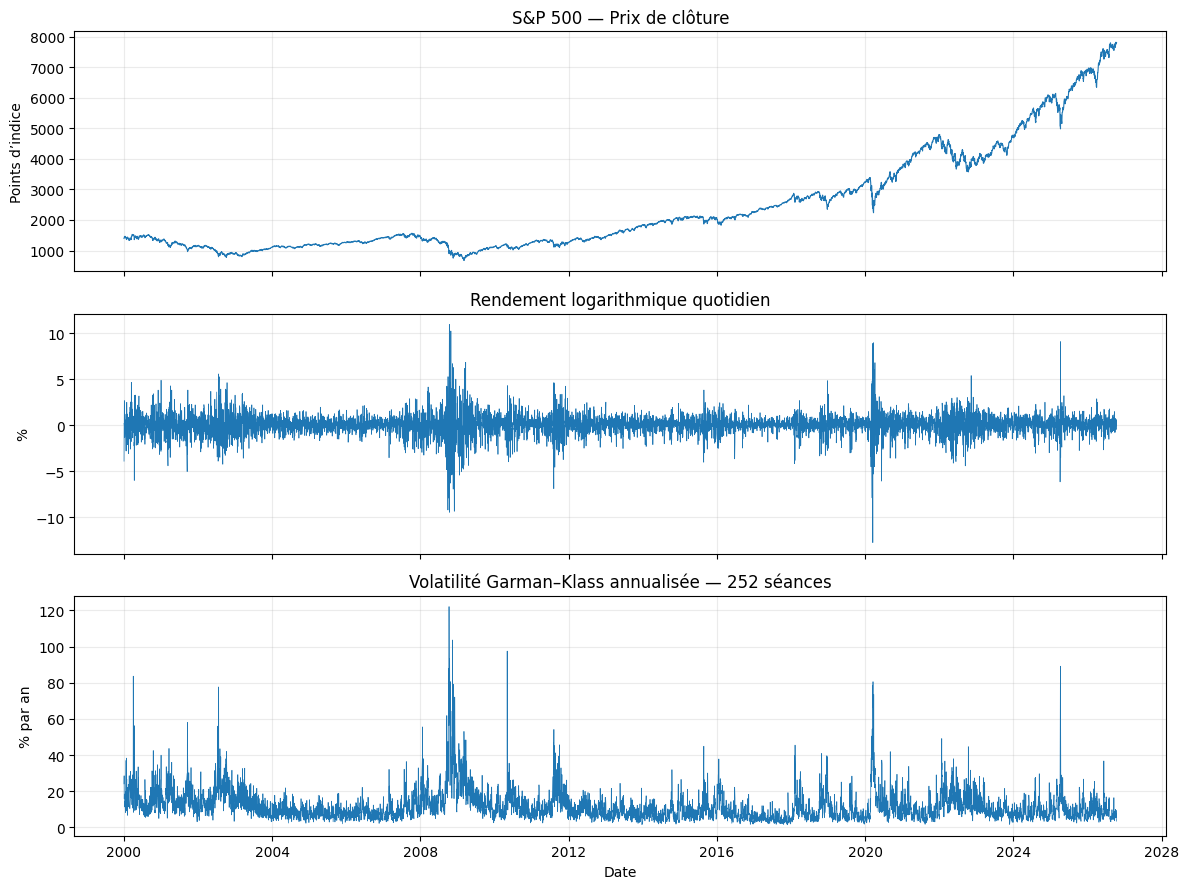

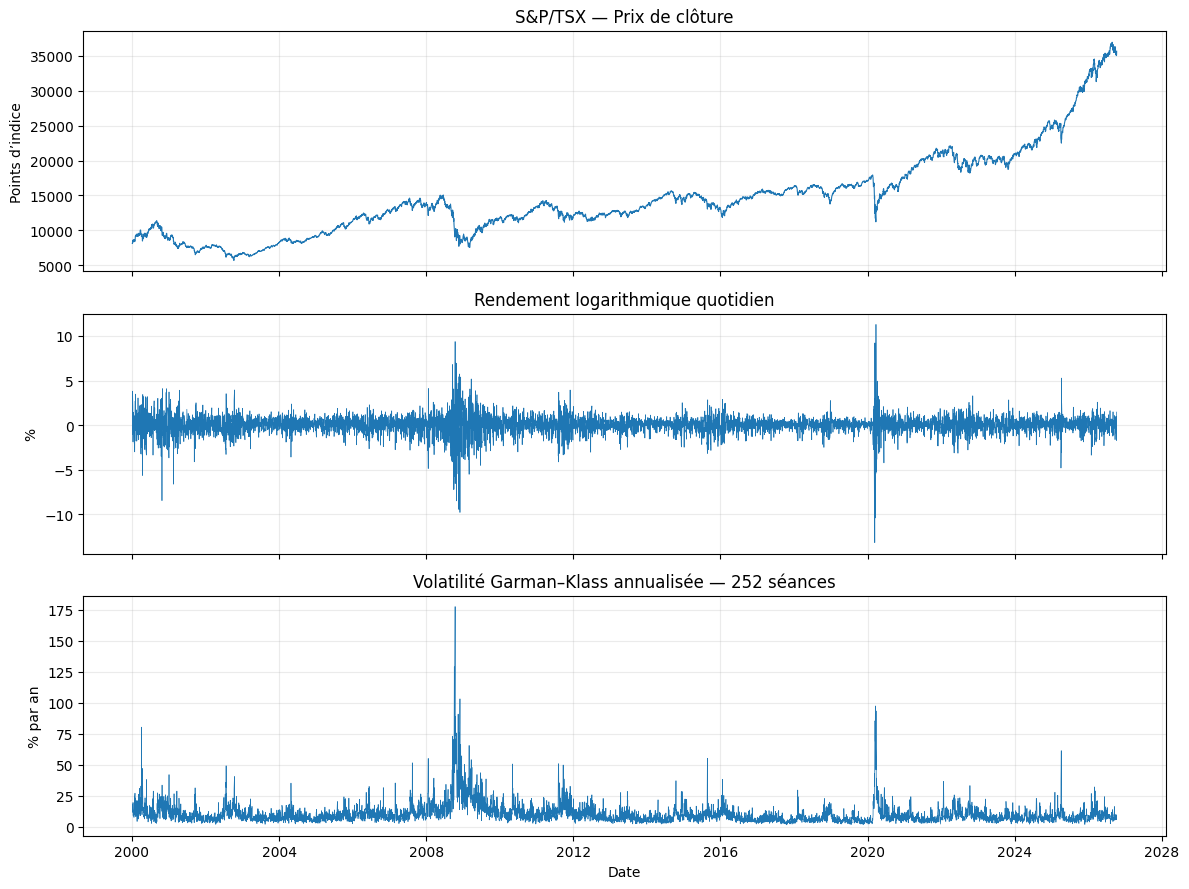

In [10]:
import matplotlib.pyplot as plt
from pathlib import Path

dossier_figures = Path("/content/t4/figures")
dossier_figures.mkdir(parents=True, exist_ok=True)

for nom, code, df in [
    ("S&P 500", "spx", spx),
    ("S&P/TSX", "tsx", tsx)
]:
    fig, axes = plt.subplots(
        3, 1, figsize=(12, 9), sharex=True
    )

    axes[0].plot(df.index, df["close"], linewidth=0.8)
    axes[0].set_title(f"{nom} — Prix de clôture")
    axes[0].set_ylabel("Points d’indice")

    axes[1].plot(df.index, df["ret"], linewidth=0.5)
    axes[1].set_title("Rendement logarithmique quotidien")
    axes[1].set_ylabel("%")

    axes[2].plot(
        df.index, np.sqrt(252 * df["rv"]), linewidth=0.5
    )
    axes[2].set_title(
        "Volatilité Garman–Klass annualisée — 252 séances"
    )
    axes[2].set_ylabel("% par an")
    axes[2].set_xlabel("Date")

    for ax in axes:
        ax.grid(alpha=0.25)

    fig.tight_layout()
    fig.savefig(
        dossier_figures / f"fig1_series_{code}.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

S&P 500 :

Le niveau de l’indice présente une tendance haussière sur l’échantillon, interrompue par plusieurs baisses marquées. Les fortes variations des rendements se concentrent sur certaines périodes, ce qui suggère une volatilité variable dans le temps et motive l’étude de modèles ARCH/GARCH.

S&P/TSX :

L’indice présente également une progression à long terme, accompagnée de replis importants. Les rendements alternent entre des périodes de faible et de forte amplitude, ce qui suggère un regroupement de volatilité à confirmer par les diagnostics statistiques.

In [11]:
from scipy import stats
from pathlib import Path

dossier_resultats = Path("/content/t4/results")
dossier_resultats.mkdir(parents=True, exist_ok=True)

def statistiques_rendements(serie):
    r = serie.dropna()
    jb = stats.jarque_bera(r)

    return pd.Series({
        "Nombre d'observations": len(r),
        "Moyenne quotidienne (%)": r.mean(),
        "Écart-type quotidien (%)": r.std(),
        "Minimum (%)": r.min(),
        "Maximum (%)": r.max(),
        "Asymétrie": stats.skew(r, bias=False),
        "Kurtosis (normale = 3)": stats.kurtosis(
            r, fisher=False, bias=False
        ),
        "Jarque-Bera : statistique": jb.statistic,
        "Jarque-Bera : p-value": jb.pvalue
    })

table1 = pd.DataFrame({
    "S&P 500": statistiques_rendements(spx["ret"]),
    "S&P/TSX": statistiques_rendements(tsx["ret"])
})

display(table1.round(6))

# Conserver les valeurs complètes dans le fichier
table1.to_csv(dossier_resultats / "table1_stats.csv")

,S&P 500,S&P/TSX
Nombre d'observations,6733.000000,6713.000000
Moyenne quotidienne (%),0.024950,0.021672
Écart-type quotidien (%),1.211659,1.076555
Minimum (%),-12.765220,-13.175800
Maximum (%),10.957197,11.294531
Asymétrie,-0.348919,-0.914828
Kurtosis (normale = 3),13.698801,19.800482
Jarque-Bera : statistique,32195.561316,79759.423800
Jarque-Bera : p-value,0.000000,0.000000


Les rendements présentent une asymétrie négative et une kurtosis nettement supérieure à 3 pour les deux indices. Le test de Jarque–Bera rejette la normalité au seuil de 5 %. Ces résultats motivent l’examen de distributions à queues épaisses, comme la loi de Student, dans les modèles de volatilité ; ils ne suffisent toutefois pas à démontrer un effet ARCH.

In [12]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

resultats_tests = []

for nom, df in [("S&P 500", spx), ("S&P/TSX", tsx)]:
    r = df["ret"].dropna()
    log_prix = np.log(df.loc[df["close"] > 0, "close"]).dropna()

    # ADF : H0 = présence d’une racine unitaire
    adf_prix = adfuller(log_prix, regression="c", autolag="AIC")
    adf_ret = adfuller(r, regression="c", autolag="AIC")

    # Ljung–Box : H0 = autocorrélations nulles jusqu’au retard 10
    lb_ret = acorr_ljungbox(r, lags=[10], return_df=True)
    lb_carre = acorr_ljungbox(r**2, lags=[10], return_df=True)

    # ARCH-LM sur les rendements centrés :
    # H0 = absence d’effet ARCH jusqu’au retard 5
    arch = het_arch(r - r.mean(), nlags=5, ddof=1)

    tests = [
        ("ADF log-prix", adf_prix[0], adf_prix[1]),
        ("ADF rendements", adf_ret[0], adf_ret[1]),
        ("Ljung-Box ret — 10 retards",
         lb_ret["lb_stat"].iloc[0], lb_ret["lb_pvalue"].iloc[0]),
        ("Ljung-Box ret² — 10 retards",
         lb_carre["lb_stat"].iloc[0], lb_carre["lb_pvalue"].iloc[0]),
        ("ARCH-LM — 5 retards", arch[0], arch[1])
    ]

    for test, statistique, pvalue in tests:
        resultats_tests.append({
            "Indice": nom,
            "Test": test,
            "Statistique": statistique,
            "p-value": pvalue,
            "Décision à 5 %": (
                "Rejet de H0" if pvalue < 0.05
                else "Non-rejet de H0"
            )
        })

table_tests = pd.DataFrame(resultats_tests)

display(table_tests.style.format({
    "Statistique": "{:.4f}",
    "p-value": "{:.3e}"
}))

table_tests.to_csv(
    dossier_resultats / "table2_tests.csv", index=False
)

/tmp/ipykernel_794/3592320848.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_prix = adfuller(log_prix, regression="c", autolag="AIC")
/tmp/ipykernel_794/3592320848.py:12: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_ret = adfuller(r, regression="c", autolag="AIC")
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: ac

,Indice,Test,Statistique,p-value,Décision à 5 %
0,S&P 500,ADF log-prix,1.0769,9.950e-01,Non-rejet de H0
1,S&P 500,ADF rendements,-19.5074,0.000e+00,Rejet de H0
2,S&P 500,Ljung-Box ret — 10 retards,97.1318,2.040e-16,Rejet de H0
3,S&P 500,Ljung-Box ret² — 10 retards,6151.9339,0.000e+00,Rejet de H0
4,S&P 500,ARCH-LM — 5 retards,1689.2662,0.000e+00,Rejet de H0
5,S&P/TSX,ADF log-prix,0.2393,9.744e-01,Non-rejet de H0
6,S&P/TSX,ADF rendements,-14.8005,2.103e-27,Rejet de H0
7,S&P/TSX,Ljung-Box ret — 10 retards,59.7278,4.081e-09,Rejet de H0
8,S&P/TSX,Ljung-Box ret² — 10 retards,6551.2733,0.000e+00,Rejet de H0
9,S&P/TSX,ARCH-LM — 5 retards,1672.2369,0.000e+00,Rejet de H0


Les tests ADF ne rejettent pas l’hypothèse de racine unitaire pour les log-prix, mais la rejettent pour les rendements. Les tests de Ljung–Box détectent une dépendance temporelle des rendements ainsi que de leurs carrés. Les tests ARCH-LM motivent l’étude de modèles de variance conditionnelle ARCH/GARCH. Il faudra également examiner la dynamique de la moyenne et vérifier les résidus des modèles estimés.

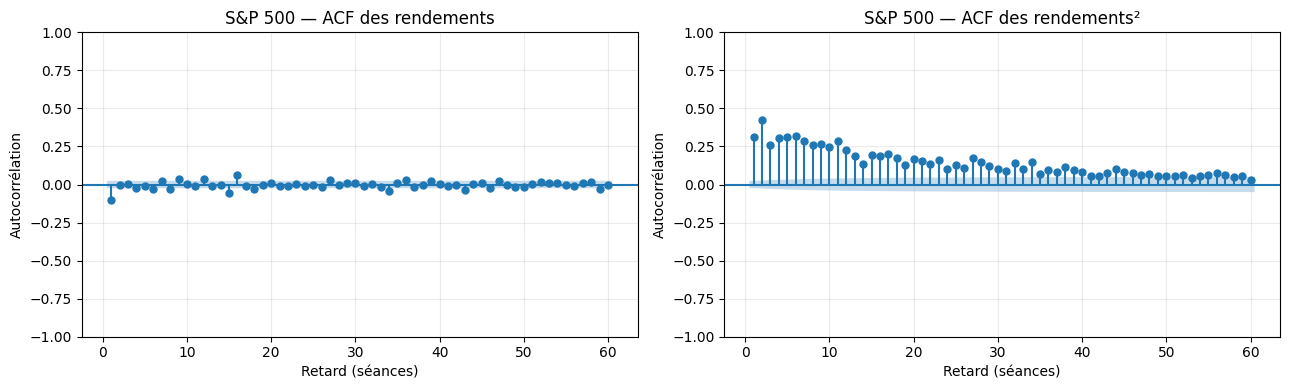

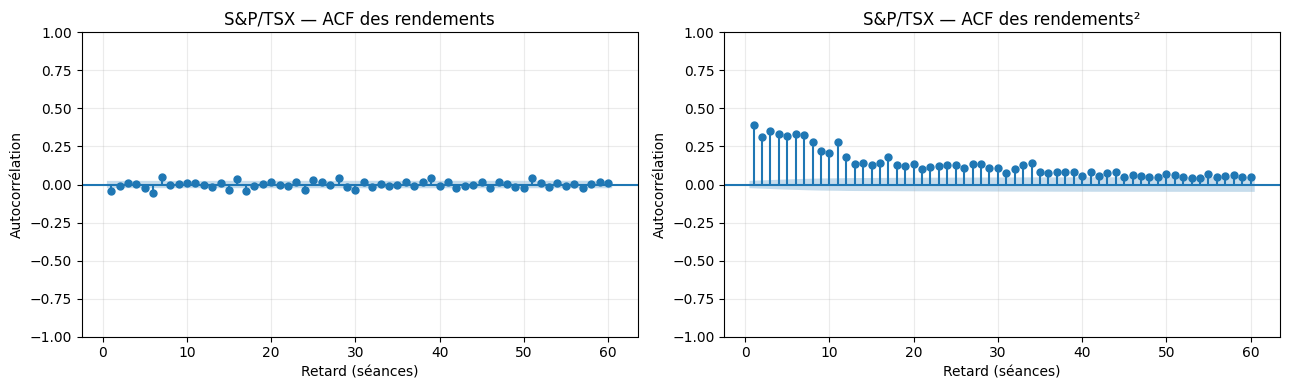

In [13]:
from statsmodels.graphics.tsaplots import plot_acf

for nom, code, df in [
    ("S&P 500", "spx", spx),
    ("S&P/TSX", "tsx", tsx)
]:
    r = df["ret"].dropna()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    plot_acf(r, lags=60, zero=False, ax=axes[0])
    plot_acf(r**2, lags=60, zero=False, ax=axes[1])

    axes[0].set_title(f"{nom} — ACF des rendements")
    axes[1].set_title(f"{nom} — ACF des rendements²")

    for ax in axes:
        ax.set_xlabel("Retard (séances)")
        ax.set_ylabel("Autocorrélation")
        ax.grid(alpha=0.25)

    fig.tight_layout()
    fig.savefig(
        dossier_figures / f"fig2_acf_{code}.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

Pour les deux indices, les autocorrélations des rendements sont de faible amplitude, malgré leur significativité globale au test de Ljung–Box. Les autocorrélations des rendements au carré décroissent lentement et restent positives au-delà de 50 séances, ce qui appuie l’utilisation de modèles de volatilité persistante, comme les modèles GARCH.

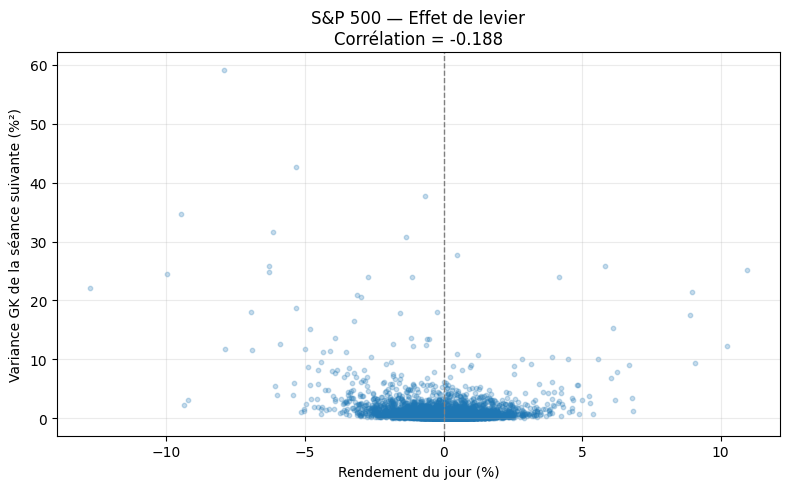

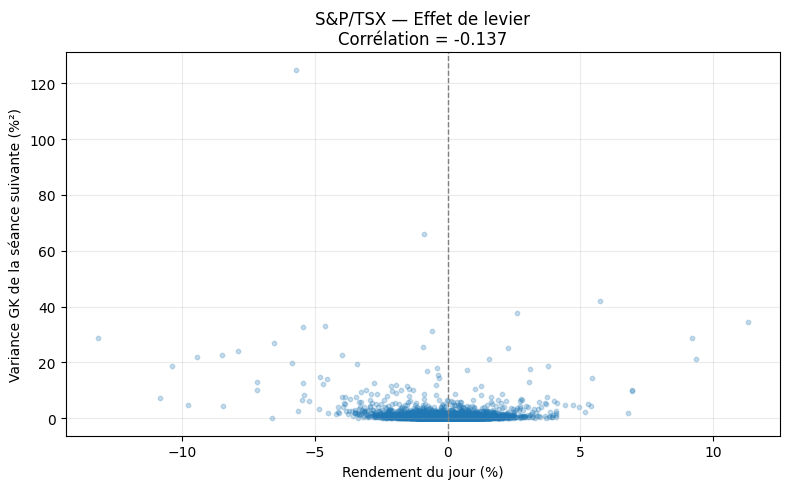

,Indice,Nombre de paires,"Corrélation ret(t), rv(t+1)"
0,S&P 500,6732,-0.187647
1,S&P/TSX,6712,-0.136891


In [14]:
resultats_levier = []

for nom, code, df in [
    ("S&P 500", "spx", spx),
    ("S&P/TSX", "tsx", tsx)
]:
    # Associer le rendement à la variance de la séance suivante
    paires = pd.DataFrame({
        "rendement": df["ret"],
        "variance_suivante": df["rv"].shift(-1)
    }).dropna()

    correlation = paires["rendement"].corr(
        paires["variance_suivante"]
    )

    resultats_levier.append({
        "Indice": nom,
        "Nombre de paires": len(paires),
        "Corrélation ret(t), rv(t+1)": correlation
    })

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.scatter(
        paires["rendement"],
        paires["variance_suivante"],
        s=10, alpha=0.25
    )
    ax.axvline(0, color="grey", linestyle="--", linewidth=1)
    ax.set_title(
        f"{nom} — Effet de levier\n"
        f"Corrélation = {correlation:.3f}"
    )
    ax.set_xlabel("Rendement du jour (%)")
    ax.set_ylabel("Variance GK de la séance suivante (%²)")
    ax.grid(alpha=0.25)

    fig.tight_layout()
    fig.savefig(
        dossier_figures / f"fig3_levier_{code}.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

table_levier = pd.DataFrame(resultats_levier)
display(table_levier)

table_levier.to_csv(
    dossier_resultats / "table3_levier.csv", index=False
)

La corrélation entre le rendement du jour et la variance Garman–Klass de la séance suivante est de −0,137. Cette association négative est compatible avec un effet de levier et motive l’examen de modèles asymétriques comme GJR-GARCH ou EGARCH, sans suffire à démontrer leur supériorité.

Conclusion du T4

L’exploration du S&P 500 et du S&P/TSX met en évidence des rendements stationnaires selon les tests ADF, tandis que l’hypothèse de racine unitaire des log-prix n’est pas rejetée. Les distributions des rendements présentent une asymétrie négative et des queues épaisses ; les tests de Jarque–Bera rejettent leur normalité.

Les autocorrélations des rendements sont faibles en amplitude, mais globalement significatives. Celles des rendements au carré persistent sur plusieurs dizaines de séances, et les tests ARCH-LM rejettent l’absence d’effets ARCH. Ces résultats motivent l’étude de modèles GARCH, en tenant compte également de la dynamique de la moyenne.

Les corrélations entre le rendement du jour et la variance Garman–Klass de la séance suivante sont de −0,188 pour le S&P 500 et de −0,137 pour le TSX. Elles motivent l’examen de modèles asymétriques comme GJR-GARCH et EGARCH. Leur performance devra être évaluée hors échantillon ; ces diagnostics ne permettent pas, à eux seuls, de désigner le meilleur modèle.

In [1]:
from pathlib import Path
import shutil
from google.colab import files

base = Path("/content/t4")

# Vérifier les fichiers produits
fichiers = (
    list((base / "figures").glob("*.png"))
    + list((base / "results").glob("*.csv"))
)

print("Fichiers à sauvegarder :", len(fichiers))
for fichier in sorted(fichiers):
    print(fichier.relative_to(base))

# Télécharger les figures et les tableaux dans une archive
archive = shutil.make_archive(
    "/content/T4_figures_resultats",
    "zip",
    root_dir=base
)
files.download(archive)

Fichiers à sauvegarder : 0


FileNotFoundError: [Errno 2] No such file or directory: '/content/t4'